# Batch processing from L1C to L2A and L2B

This notebook processes a time series of Sentinel-2 L1C images (or Landsat Collection 2 Level-1 images)
of one or several tiles, image by image, through the two processors of the chain:

- [GRS](https://grs.readthedocs.io/en/latest) computes the **L2A** product (atmospheric and sunglint corrected remote-sensing
  reflectance $R_{rs}$, masks, aerosols) from the Level-1 image;
- [GRSl2bgen](https://grsl2bgen.readthedocs.io/en/latest) computes the **L2B** product (water-quality parameters, optical water types)
  from the L2A product, as soon as it is written.

Each image gets a **profiling file** with the wall time, CPU time and peak memory of each step and its
memory curve, to size the machine or the parallelism of a large batch. The notebook merges the batch
notebooks of [GRS](https://grs.readthedocs.io/en/latest/examples/batch.html) and [GRSl2bgen](https://grsl2bgen.readthedocs.io/en/latest/tutorials/batch.html):

1. **Configuration**: folders, tiles, date range, auxiliary data, options of the two processors.
2. **List the Level-1 images** found on disk, with their cloud cover, and select a date range.
3. **Auxiliary data and output naming**: CAMS file of the month, optional DEM, names of the L2A and L2B
   products and of the profiling file.
4. **Profiling**: memory sampled in a background thread, CPU and wall times of each step.
5. **Run the batch**: L2A then L2B for each image; products already written are skipped, a failure is
   logged and does not stop the batch, and a summary table is saved.
6. **Profiles** of the batch, and memory curve of one image.
7. **Quick look** at the L2A and L2B products of one image.

For long batches, the command line is more robust than a notebook: each image runs in its own Python
process, so that the memory is fully released between images (see the last section).

```{note}
The notebook is rendered with the outputs of a short run: the three images of 1 and 2 August 2025 of
tile 31TEJ (Gulf of Lion: Thau lagoon and the coast of Montpellier), at 20 m, with GRS 3.1.0. The Level-1 images and auxiliary data are not distributed with grstbx: set the paths of the
configuration cell to run it on your own data. The INFO log of the processors is left out: it is in the
log file of each product.
```

In [1]:
import os
import gc
import re
import glob
import json
import time
import shutil
import socket
import logging
import platform
import threading
import warnings
import contextlib
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import xarray as xr
import matplotlib.pyplot as plt

import grs
from grs import config as grs_config
from grs.run import set_ofile
import GRSl2bgen
from GRSl2bgen.run import default_output_name
from GRSl2bgen.logger import RunLogger
from GRSl2bgen.stac import item_path, write_stac_item

opj = os.path.join

# INFO messages of the processing chains; set to logging.WARNING for a quieter batch
logging.getLogger().setLevel(logging.INFO)
# deprecation notices of the dependencies, and the chunk hint of the L2A files: not useful here
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='The specified chunks separate the stored chunks')
warnings.filterwarnings('ignore', message='Consolidated metadata')
warnings.filterwarnings('ignore', message='Significant no-data areas detected')   # OmniCloudMask, swath edge
warnings.filterwarnings('ignore', message='Dataset has no geotransform')

print(f'grs: {grs.__version__}, GRSl2bgen: {GRSl2bgen.__version__}')

grs: 3.1.0, GRSl2bgen: 1.2.0dev0


## 1. Configuration

The Level-1 images are expected in a `<idir>/<tile>/YYYY/MM/DD/<image>` tree; the L2A and L2B products
are written to the same tree under `<l2a_dir>/<tile>` and `<l2b_dir>/<tile>`.

| Parameter | Description |
|---|---|
| `idir`, `l2a_dir`, `l2b_dir` | root folders of the Level-1 inputs, of the L2A and of the L2B outputs |
| `tiles` | tile sub-folders to process (e.g. `31TEJ`, or a Landsat path/row `199027`) |
| `pattern` | glob pattern of the Level-1 image names (`'S2*.SAFE'`, `'L*_L1*'` for Landsat) |
| `start_date`, `end_date` | date range to process (inclusive) |
| `cams_file_template` | CAMS file of the month of the acquisition, formatted with the image `date` (mandatory, see the [CAMS tutorial of GRS](https://grs.readthedocs.io/en/latest/examples/auxdata.html)) |
| `dem_file_template` | DEM GeoTIFF of the tile, formatted with `tile`; `None` or missing file: no DEM (fine over the sea) |
| `resolution` | pixel size (m) of the L2A product (10, 20 or 60 for Sentinel-2, 30 for Landsat) |
| `aot_resolution` | GRS: pixel size (m) of the coarse grid of the aerosol retrieval, multiple of `resolution` |
| `l2a_ext` | GRS: `'.zarr'` (Zarr store with overviews) or `'.nc'` (NetCDF, plus a `_anc.nc` ancillary file) |
| `max_cloud_cover` | skip the images whose Level-1 cloud cover (0-1) is greater or equal |
| `opac_model`, `scale_aot` | GRS: aerosol model (`None`: from CAMS), scaling factor of the CAMS AOD |
| `levname`, `suffix` | GRS: level name and suffix of the L2A name (`None`: `_V<grs version>`), as `--levname` / `--suffix` of the `grs` command line |
| `out_ext`, `pyramid` | GRSl2bgen: `'.nc'` (NetCDF) or `'.zarr'`; for `.zarr`, a multiscale pyramid for cloud visualisation |
| `stac` | GRSl2bgen: write the STAC Item of each L2B product, last; the product is then complete when its Item exists |
| `persist_input` | GRSl2bgen: keep the masked L2A raster in memory (faster, needs more RAM) |
| `keep_l2a` | keep the L2A product once its L2B product is written (`False` saves disk space) |
| `overwrite` | reprocess the images whose products already exist |
| `memory_interval` | sampling interval (s) of the memory curve of the profiles |

A full Sentinel-2 tile at 20 m needs about 10 GB of memory with GRS 3.1.0, and about 6 GB with
GRSl2bgen (70 s); the profiles of section 6 give the figures of your machine. Starting Jupyter with the
environment variable `MALLOC_ARENA_MAX=2` (already set by the `grs` command) lets the memory freed by the
processing threads be reused from one image to the next.

In [2]:
idir = '/data/satellite/Sentinel-2/L1C'
l2a_dir = '/data/satellite/Sentinel-2/batch_demo/L2A'
l2b_dir = '/data/satellite/Sentinel-2/batch_demo/L2B'
tiles = ['31TEJ']
pattern = 'S2*.SAFE'
start_date, end_date = '2025-08-01', '2025-08-02'

cams_file_template = '/data/cams/world/cams_forecast_{date:%Y-%m}.nc'
dem_file_template = '/home/harmel/Dropbox/Dropbox/satellite/dem/COP-DEM_GLO-30-DGED_{tile}.tif'   # or None

# GRS (L2A)
resolution = 20        # m
aot_resolution = 480   # m, multiple of resolution
l2a_ext = '.zarr'      # '.zarr' or '.nc'
max_cloud_cover = 0.6  # 0-1
opac_model = None      # e.g. 'DESE_rh70' to force desert dust
scale_aot = 1
levname = 'L2AGRS'
suffix = None          # None: '_V<grs version>'

# GRSl2bgen (L2B)
out_ext = '.nc'        # '.nc' or '.zarr'
pyramid = False        # only for '.zarr'
stac = True
persist_input = False

keep_l2a = True
overwrite = False
memory_interval = 0.5  # s

The radiative transfer look-up tables (LUT) of GRS are read from the folder set in the user
configuration of GRS, `~/.config/grs/config.yml` (created with `grs_config --init`, see the
[installation of GRS](https://grs.readthedocs.io/en/latest/installation.html)), or by the environment variable `GRS_DATA_ROOT`.
Check that they are found before starting a long batch:

In [3]:
print(f'LUT folder set by: {grs_config.data_root_source()}')
for name, path, exists in grs_config.lut_status():
    print(f"{name:13s} {path}: {'found' if exists else 'MISSING, see grs_config --download'}")

LUT folder set by: user configuration
toa           /data/grs/grsdata/toa_lut_opac_wind_v3.nc: found
transmittance /data/grs/grsdata/transmittance_lut_opac_wind_v3.nc: found


## 2. List the Level-1 images

The images are indexed by their acquisition date, taken from the `YYYY/MM/DD` folders, so that a date
range can be selected with `.loc`. The cloud cover is read from the Level-1 metadata
(`MTD_MSIL1C.xml` for Sentinel-2, `*_MTL.txt` for Landsat); it is `NaN` when it cannot be found.

In [4]:
def cloud_cover(path):
    """Level-1 cloud cover (0-1) from the image metadata, NaN if not found."""
    patterns = [('MTD_MSIL1C.xml', r'<Cloud_Coverage_Assessment>\s*([\d.]+)'),
                ('*_MTL.txt', r'\bCLOUD_COVER\s*=\s*"?([\d.]+)')]
    for metadata, regex in patterns:
        for file in glob.glob(opj(path, metadata)):
            with open(file) as f:
                match = re.search(regex, f.read())
            if match:
                return float(match.group(1)) / 100
    return np.nan


def list_images(idir, tiles, pattern='S2*.SAFE'):
    """Table of the Level-1 images found in <idir>/<tile>/YYYY/MM/DD/, indexed by acquisition date."""
    rows = []
    for tile in tiles:
        for path in sorted(glob.glob(opj(idir, tile, '*', '*', '*', pattern))):
            year, month, day = Path(path).parts[-4:-1]
            rows.append(dict(date=pd.Timestamp(f'{year}-{month}-{day}'), tile=tile,
                             name=os.path.basename(path.rstrip('/')), path=path))
    df = pd.DataFrame(rows, columns=['date', 'tile', 'name', 'path'])
    df['cloud_cover'] = df['path'].map(cloud_cover)
    return df.set_index('date').sort_index()


images = list_images(idir, tiles, pattern)
print(f'{len(images)} Level-1 images found in {idir} for tiles {tiles}')
selection = images.loc[start_date:end_date]
print(f'{len(selection)} images between {start_date} and {end_date}')
selection[['tile', 'name', 'cloud_cover']]

548 Level-1 images found in /data/satellite/Sentinel-2/L1C for tiles ['31TEJ']
3 images between 2025-08-01 and 2025-08-02


,tile,name,cloud_cover
date,,,
2025-08-01,31TEJ,S2A_MSIL1C_20250801T104041_N0511_R008_T31TEJ_2...,0.352517
2025-08-01,31TEJ,S2B_MSIL1C_20250801T102559_N0511_R108_T31TEJ_2...,0.162438
2025-08-02,31TEJ,S2C_MSIL1C_20250802T105051_N0511_R051_T31TEJ_2...,0.082500


## 3. Auxiliary data and output naming

For each image:

- the **CAMS file** is the one of the month of the acquisition; images without CAMS file are skipped;
- the **DEM** is the GeoTIFF of the tile, if it exists;
- the **L2A product** is named as with the `grs` command line (`grs.run.set_ofile`: level name of the
  image replaced by `levname`, plus `suffix`), in its own folder `<l2a_dir>/<tile>/YYYY/MM/DD/<name>/` with
  the Zarr store `<name>.zarr` (or the NetCDF product `<name>.nc` and its ancillary data `<name>_anc.nc`)
  and the log `log_file.log`;
- the **L2B product** is named as with the `GRSl2bgen` command line (`L2AGRS` replaced by `L2B`), in
  its own folder `<l2b_dir>/<tile>/YYYY/MM/DD/<name>/` with the product `<name>.nc` (or `.zarr`), its
  log `<name>.log` and its STAC Item `<name>.json`, written last;
- the **profiling file** is `<l2b_dir>/profiles/<tile>/<Level-1 name>_profile.json`.

```
S2A_MSIL1C_20250801T104041_N0511_R008_T31TEJ_20250801T131318.SAFE                      Level-1
S2A_MSIL2AGRS_20250801T104041_N0511_R008_T31TEJ_20250801T131318_V3.1.0/<name>.zarr     L2A
S2A_MSIL2B_20250801T104041_N0511_R008_T31TEJ_20250801T131318_V3.1.0/<name>.nc          L2B
```

An image is **done** when its L2B product is complete (STAC Item present, or the product itself if
`stac=False`); its L2A product is reused when it exists, so that a batch stopped between the two steps
restarts from the L2B step.

In [5]:
def dem_file(tile):
    if dem_file_template is None:
        return None
    file = dem_file_template.format(tile=tile)
    return file if os.path.exists(file) else None


def l2a_path(row, date):
    """L2A product: <l2a_dir>/<tile>/YYYY/MM/DD/<name>/<name><l2a_ext>, as with the grs command line."""
    folder = set_ofile(row['name'], odir=opj(l2a_dir, row['tile'], date.strftime('%Y/%m/%d')),
                       level_name=levname, suffix=suffix if suffix is not None else f'_V{grs.__version__}')
    return str(folder / (folder.name + l2a_ext))


def l2b_path(l2a, row, date):
    """L2B product: <l2b_dir>/<tile>/YYYY/MM/DD/<name>/<name><out_ext>."""
    name = default_output_name(os.path.dirname(l2a))[:-len('.nc')]
    return opj(l2b_dir, row['tile'], date.strftime('%Y/%m/%d'), name, name + out_ext)


def profile_path(row):
    return opj(l2b_dir, 'profiles', row['tile'], Path(row['name']).stem + '_profile.json')


def l2b_done(l2b):
    return os.path.exists(item_path(l2b) if stac else l2b)


selection = selection.assign(
    cams_file=[cams_file_template.format(date=date) for date in selection.index],
    dem_file=selection['tile'].map(dem_file),
    l2a=[l2a_path(row, date) for date, row in selection.iterrows()])
selection['l2b'] = [l2b_path(row['l2a'], row, date) for date, row in selection.iterrows()]
selection['profile'] = [profile_path(row) for _, row in selection.iterrows()]
selection['cams_ok'] = selection['cams_file'].map(os.path.exists)
selection['cloudy'] = selection['cloud_cover'] >= max_cloud_cover
selection['done'] = selection['l2b'].map(l2b_done)

todo = ~selection['done'] & selection['cams_ok'] & ~selection['cloudy']
print(f"{selection['done'].sum()} already processed, {selection['cloudy'].sum()} too cloudy, "
      f"{(~selection['cams_ok']).sum()} without CAMS file, {todo.sum()} to process")
selection[['name', 'cloud_cover', 'cams_ok', 'dem_file', 'done']]

3 already processed, 0 too cloudy, 0 without CAMS file, 0 to process


,name,cloud_cover,cams_ok,dem_file,done
date,,,,,
2025-08-01,S2A_MSIL1C_20250801T104041_N0511_R008_T31TEJ_2...,0.352517,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,True
2025-08-01,S2B_MSIL1C_20250801T102559_N0511_R108_T31TEJ_2...,0.162438,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,True
2025-08-02,S2C_MSIL1C_20250802T105051_N0511_R051_T31TEJ_2...,0.082500,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,True


## 4. Profiling

`Profiler` follows the processing of one image: a background thread samples the resident memory (RSS)
of the kernel and of its child processes every `memory_interval` seconds, and each step (`L2A`, `L2B`)
records its wall time, its CPU time (all the threads of the process, so it exceeds the wall time when
the processing runs in parallel) and the RSS at its start, peak and end. The peak memory of a step is
the one to compare with the RAM of the machine to choose how many images to process in parallel.

The profile is written as JSON: the image, the machine (host, CPUs, RAM), the versions of the
processors, the steps and the memory curve (`memory`: time in s since the start, RSS in MB).

In [6]:
class Profiler:
    """Wall time, CPU time and memory of the processing steps of one image."""

    def __init__(self, image, interval=0.5):
        self.image, self.interval = image, interval
        self.process = psutil.Process()
        self.start = dt.datetime.now()
        self.t0 = time.perf_counter()
        self.steps, self.memory = [], []
        self._stop = threading.Event()
        self._thread = threading.Thread(target=self._sample, daemon=True)
        self._thread.start()

    def rss(self):
        """Resident memory (MB) of the process and its children."""
        rss = self.process.memory_info().rss
        for child in self.process.children(recursive=True):
            with contextlib.suppress(psutil.Error):
                rss += child.memory_info().rss
        return rss / 2**20

    def cpu(self):
        t = self.process.cpu_times()
        return t.user + t.system + t.children_user + t.children_system

    def _sample(self):
        while not self._stop.is_set():
            self.memory.append((round(time.perf_counter() - self.t0, 2), round(self.rss(), 1)))
            self._stop.wait(self.interval)

    @contextlib.contextmanager
    def step(self, name):
        """Profile the block as the step `name`; its status is 'failed' if it raises."""
        record = dict(step=name, status='done', start_s=round(time.perf_counter() - self.t0, 2),
                      rss_start_mb=round(self.rss(), 1))
        cpu0, t0, n0 = self.cpu(), time.perf_counter(), len(self.memory)
        try:
            yield record
        except BaseException:
            record['status'] = 'failed'
            raise
        finally:
            end = round(self.rss(), 1)
            wall = time.perf_counter() - t0
            record.update(wall_s=round(wall, 2), cpu_s=round(self.cpu() - cpu0, 2),
                          cpu_load=round((self.cpu() - cpu0) / wall, 2) if wall else None,
                          rss_peak_mb=max([end, record['rss_start_mb']] + [m for _, m in self.memory[n0:]]),
                          rss_end_mb=end)
            self.steps.append(record)

    def skip(self, name, status='skipped'):
        self.steps.append(dict(step=name, status=status))

    def write(self, path, **info):
        """Stop the sampling and write the profile as JSON."""
        self._stop.set()
        self._thread.join()
        profile = dict(
            image=self.image, start=self.start.isoformat(timespec='seconds'),
            total_s=round(time.perf_counter() - self.t0, 2),
            host=socket.gethostname(), cpus=os.cpu_count(),
            ram_gb=round(psutil.virtual_memory().total / 2**30, 1), python=platform.python_version(),
            versions={'grs': grs.__version__, 'GRSl2bgen': GRSl2bgen.__version__},
            **info, steps=self.steps, memory=self.memory)
        os.makedirs(os.path.dirname(path), exist_ok=True)
        with open(path, 'w') as f:
            json.dump(profile, f, indent=1, default=str)

## 5. Run the batch

For each image:

- it is **skipped** if its L2B product is complete (unless `overwrite=True`), so that the batch can be
  interrupted and restarted at any time; it is also skipped if it is too cloudy or has no CAMS file;
- **L2A**: `grs.Process.execute` sets up the processing (lazily, with dask) and `write_output` computes
  and writes the product, chunk by chunk, with a copy of the processing messages in `log_file.log`; an
  existing L2A product is reused;
- **L2B**: `GRSl2bgen.Process` reads the L2A product (Zarr store, or NetCDF files) and writes the
  L2B product; its log is written to `<name>.log` by `GRSl2bgen.logger.RunLogger`, and the STAC Item
  last;
- a **failing** step is logged, its partial output removed so that the image is retried at the next run,
  and the batch goes on; the L2B step is not run when the L2A step fails;
- the **profile** of the image is written, whatever the outcome.

The memory of an image is released (`gc.collect()`) before the next one.

In [7]:
def remove_output(path):
    """Remove a product: file, or folder."""
    if os.path.isdir(path):
        shutil.rmtree(path)
    elif os.path.isfile(path):
        os.remove(path)


def run_l2a(row):
    """GRS: Level-1 image -> L2A product folder."""
    outdir = os.path.dirname(row['l2a'])
    remove_output(outdir)
    os.makedirs(outdir)
    # copy of the processing messages in the product folder
    handler = logging.FileHandler(opj(outdir, 'log_file.log'))
    handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
    logging.getLogger().addHandler(handler)
    process = None
    try:
        process = grs.Process()
        process.execute(row['path'], odir=row['l2a'], cams_file=row['cams_file'], dem_file=row['dem_file'],
                        resolution=resolution, aot_resolution=aot_resolution,
                        opac_model=opac_model, scale_aot=scale_aot)
        process.write_output()
    except Exception:
        logging.exception(f"L2A processing failed: {row['path']}")
        remove_output(outdir)
        raise
    finally:
        logging.getLogger().removeHandler(handler)
        handler.close()
        process = None
        gc.collect()


def run_l2b(row):
    """GRSl2bgen: L2A product folder -> L2B product folder (product, log, STAC Item)."""
    l2a, l2b = os.path.dirname(row['l2a']), row['l2b']
    remove_output(item_path(l2b))      # the Item first: the product is not complete any more
    remove_output(l2b)
    os.makedirs(os.path.dirname(l2b), exist_ok=True)
    log_file = os.path.splitext(l2b)[0] + '.log'
    try:
        # the traceback of a failure is written to the log by RunLogger
        with RunLogger(log_file, log_console=True):
            logging.info(f'GRSl2bgen {GRSl2bgen.__version__}: {l2a} -> {l2b}')
            process = GRSl2bgen.Process(l2a, l2b, pyramid=pyramid, persist_input=persist_input)
            process.run()
            del process
        if stac:
            write_stac_item(l2b, l2a=l2a, log_file=log_file)
    except Exception:
        remove_output(l2b)
        raise
    finally:
        gc.collect()


def process_image(row):
    """L2A then L2B of one image; return its record for the summary."""
    record = dict(tile=row['tile'], name=row['name'], status='done', error='', l2a='', l2b='',
                  duration_s=0.)
    if not row['cams_ok']:
        return record | dict(status='no_cams', error=f"missing {row['cams_file']}")
    if row['cloudy']:
        return record | dict(status='cloudy')
    if l2b_done(row['l2b']) and not overwrite:
        return record | dict(status='skipped')

    profiler = Profiler(row['name'], interval=memory_interval)
    try:
        if os.path.exists(row['l2a']) and not overwrite:
            profiler.skip('L2A', 'reused')
        else:
            with profiler.step('L2A'):
                run_l2a(row)
        record['l2a'] = 'done'
        with profiler.step('L2B'):
            run_l2b(row)
        record['l2b'] = 'done'
        if not keep_l2a:
            remove_output(os.path.dirname(row['l2a']))
    except Exception as e:
        step = 'L2A' if not record['l2a'] else 'L2B'
        if step == 'L2A':
            profiler.skip('L2B', 'not run')
        record |= dict(status=f'{step} failed', error=f'{type(e).__name__}: {e}')
    finally:
        profiler.write(row['profile'], l1=row['path'], l2a=row['l2a'], l2b=row['l2b'],
                       resolution=resolution, status=record['status'])
        record['duration_s'] = round(time.perf_counter() - profiler.t0, 1)
    return record


records = []
for i, (date, row) in enumerate(selection.iterrows(), start=1):
    record = process_image(row)
    records.append(dict(date=date) | record)
    print(f"[{i}/{len(selection)}] {record['status']:10s} {row['name']} ({record['duration_s']:.0f} s)")

summary = pd.DataFrame(records)
summary['status'].value_counts()

[1/3] done       S2A_MSIL1C_20250801T104041_N0511_R008_T31TEJ_20250801T131318.SAFE (309 s)


[2/3] done       S2B_MSIL1C_20250801T102559_N0511_R108_T31TEJ_20250801T140637.SAFE (194 s)


[3/3] done       S2C_MSIL1C_20250802T105051_N0511_R051_T31TEJ_20250802T142718.SAFE (180 s)


status
done    3
Name: count, dtype: int64

The summary is saved as a CSV file in `l2b_dir`. Failed images can be inspected below (see also the
log files of their products) and reprocessed by running the batch again.

In [8]:
if len(summary):
    summary_file = opj(l2b_dir, f'l1c_l2b_batch_{dt.datetime.now():%Y%m%dT%H%M%S}.csv')
    os.makedirs(l2b_dir, exist_ok=True)
    summary.to_csv(summary_file, index=False)
    print(f'summary saved to {summary_file}')

summary[summary.status.str.contains('failed|no_cams')][['date', 'tile', 'status', 'error', 'name']]

summary saved to /data/satellite/Sentinel-2/batch_demo/L2B/l1c_l2b_batch_20261023T112238.csv


,date,tile,status,error,name


## 6. Profiles

The profiling files of the selection, one row per image and step: wall and CPU times, CPU load (CPU
time / wall time: about the number of busy cores) and peak memory.

In [9]:
def read_profiles(paths):
    rows = []
    for path in paths:
        if not os.path.exists(path):
            continue
        with open(path) as f:
            profile = json.load(f)
        for step in profile['steps']:
            rows.append(dict(image=Path(profile['image']).stem, start=profile['start']) | step)
    return pd.DataFrame(rows)


profiles = read_profiles(selection['profile'])
columns = ['image', 'step', 'status', 'wall_s', 'cpu_s', 'cpu_load', 'rss_start_mb', 'rss_peak_mb', 'rss_end_mb']
profiles.reindex(columns=columns)

,image,step,status,wall_s,cpu_s,cpu_load,rss_start_mb,rss_peak_mb,rss_end_mb
0,S2A_MSIL1C_20250801T104041_N0511_R008_T31TEJ_2...,L2A,done,233.81,3003.41,12.85,306.3,12375.4,2931.2
1,S2A_MSIL1C_20250801T104041_N0511_R008_T31TEJ_2...,L2B,done,74.85,221.90,2.96,2931.2,7695.0,5559.5
2,S2B_MSIL1C_20250801T102559_N0511_R108_T31TEJ_2...,L2A,done,126.76,1445.82,11.41,5559.5,10272.2,5179.6
3,S2B_MSIL1C_20250801T102559_N0511_R108_T31TEJ_2...,L2B,done,66.71,208.46,3.13,5179.6,7676.1,5295.6
4,S2C_MSIL1C_20250802T105051_N0511_R051_T31TEJ_2...,L2A,done,116.95,1279.90,10.94,5295.6,10204.8,5210.8
5,S2C_MSIL1C_20250802T105051_N0511_R051_T31TEJ_2...,L2B,done,63.32,200.73,3.17,5210.8,7626.7,5210.8


In [10]:
done = profiles[profiles.status == 'done']
if len(done):
    stats = done.groupby('step').agg(images=('image', 'size'), wall_s=('wall_s', 'mean'),
                                     cpu_load=('cpu_load', 'mean'), peak_mb=('rss_peak_mb', 'max'))
    display(stats.round(1))

,images,wall_s,cpu_load,peak_mb
step,,,,
L2A,3,159.2,11.7,12375.4
L2B,3,68.3,3.1,7695.0


Memory curve of the last image processed, with its steps; the peak of each step is marked:

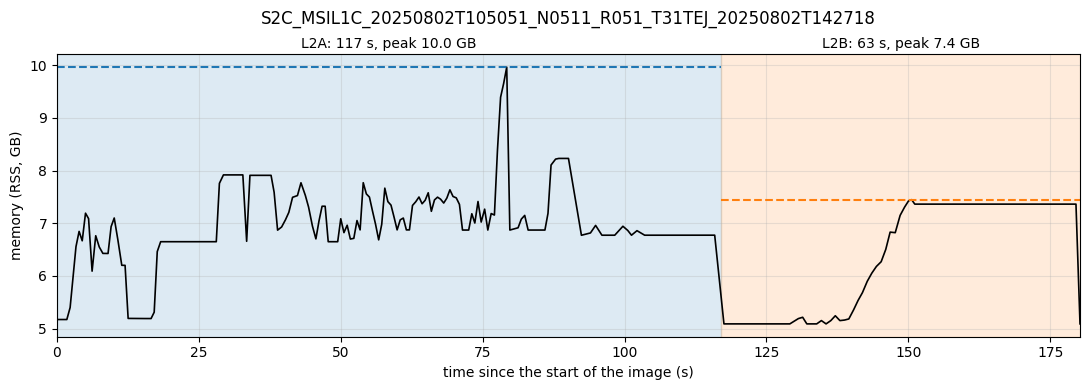

In [11]:
profiled = [p for p in selection['profile'] if os.path.exists(p)]
if not profiled:
    raise FileNotFoundError('no profile in the selection: check the summary above')
with open(profiled[-1]) as f:
    profile = json.load(f)

t, rss = np.array(profile['memory']).T
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, rss / 1024, color='k', lw=1.2)
colors = {'L2A': 'tab:blue', 'L2B': 'tab:orange'}
for step in profile['steps']:
    if step['status'] != 'done':
        continue
    start, end = step['start_s'], step['start_s'] + step['wall_s']
    ax.axvspan(start, end, color=colors.get(step['step'], 'grey'), alpha=0.15)
    ax.text((start + end) / 2, 1.01, f"{step['step']}: {step['wall_s']:.0f} s, peak {step['rss_peak_mb'] / 1024:.1f} GB",
            transform=ax.get_xaxis_transform(), ha='center', va='bottom')
    ax.axhline(step['rss_peak_mb'] / 1024, xmin=start / t.max(), xmax=end / t.max(),
               color=colors.get(step['step'], 'grey'), ls='--')
ax.set(xlabel='time since the start of the image (s)', ylabel='memory (RSS, GB)', xlim=(0, t.max()))
ax.set_title(Path(profile['image']).stem, pad=22)
ax.grid(alpha=0.3)
plt.tight_layout()

## 7. Quick look at the products of one image

The image with the largest proportion of valid water pixels is displayed (an image of a neighbouring orbit
may only cover the edge of the tile): true-colour composite of the remote-sensing reflectance $R_{rs}$ of the valid water pixels of the L2A
product (`mask == 0`), and three water-quality parameters of the L2B product: chlorophyll-a, turbidity
and the closest optical water type.

valid water pixels (%): [13.4, 5.6, 0.0]


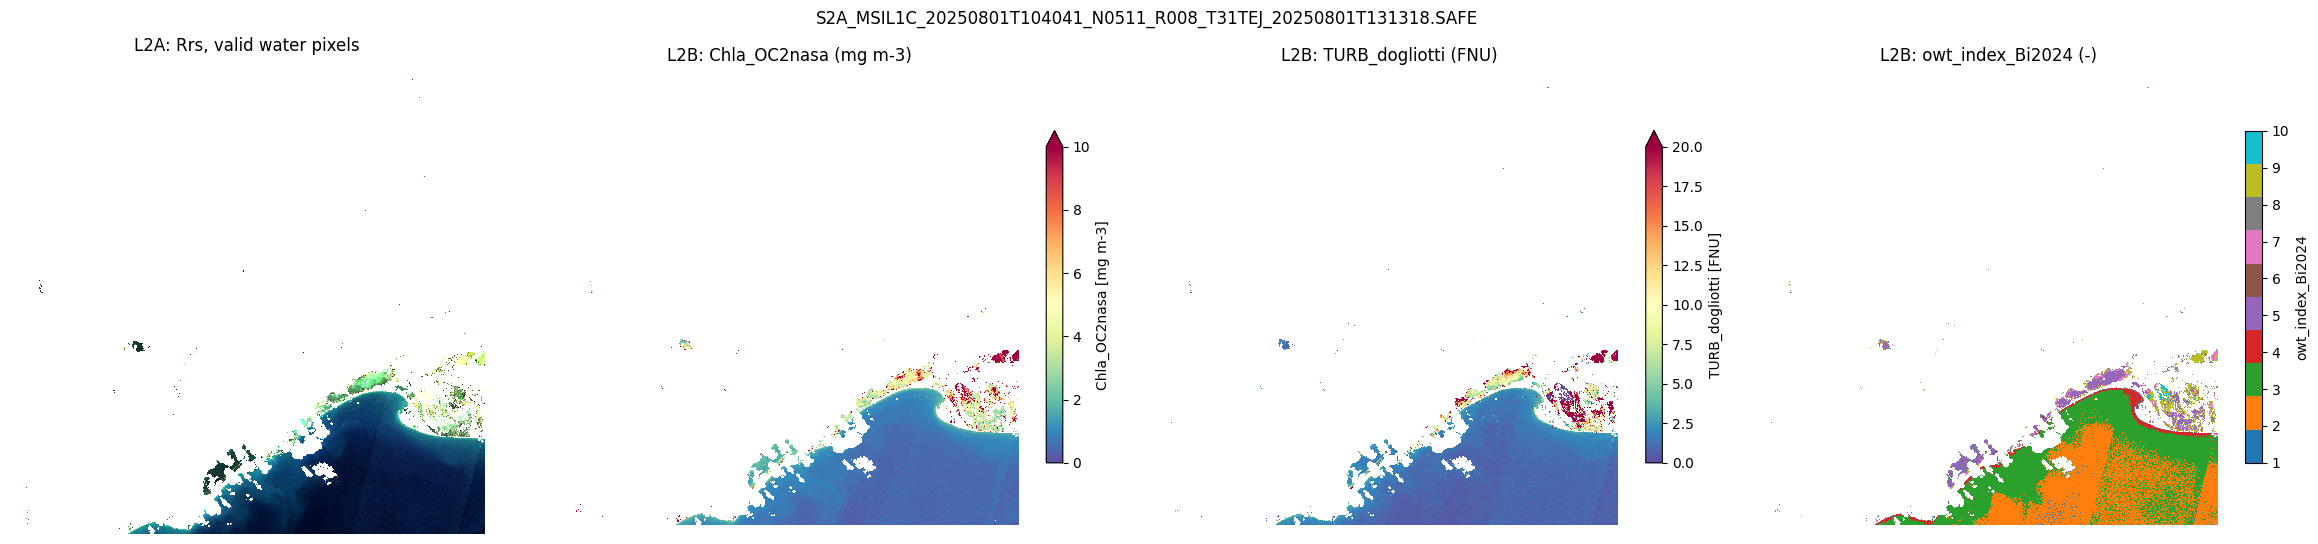

In [12]:
done = selection[selection['l2b'].map(l2b_done) & selection['l2a'].map(os.path.exists)]
if done.empty:
    raise FileNotFoundError('no image with both products in the selection: check the summary above')


def open_l2a(path, level=0):
    """L2A product; level k of the Zarr pyramid is 2**k coarser (NetCDF: one pixel out of 2**k)."""
    if path.endswith('.zarr'):
        return xr.open_zarr(path, group=str(level))
    ds = xr.open_dataset(path, decode_coords='all')
    return ds.isel(x=slice(None, None, 2**level), y=slice(None, None, 2**level))


# proportion of valid water pixels, on a coarse level
valid = done['l2a'].map(lambda path: float((open_l2a(path, level=3).mask == 0).mean()))
print('valid water pixels (%):', (100 * valid).round(1).tolist())
row = done.iloc[int(np.argmax(valid.values))]
l2a = open_l2a(row['l2a'])
l2b = xr.open_dataset(row['l2b'], decode_coords='all') if out_ext == '.nc' else xr.open_zarr(row['l2b'])

params = [('Chla_OC2nasa', dict(cmap='Spectral_r', vmin=0, vmax=10)),
          ('TURB_dogliotti', dict(cmap='Spectral_r', vmin=0, vmax=20)),
          ('owt_index_Bi2024', dict(cmap='tab10'))]
params = [(p, kw) for p, kw in params if p in l2b]
fig, axs = plt.subplots(1, 1 + len(params), figsize=(6 * (1 + len(params)), 5.5))
water = l2a.mask == 0
l2a.Rrs.sel(wl=[665, 560, 490], method='nearest').where(water).plot.imshow(rgb='wl', robust=True, ax=axs[0])
axs[0].set_title('L2A: Rrs, valid water pixels')
for ax, (param, kwargs) in zip(axs[1:], params):
    l2b[param].squeeze().plot.imshow(ax=ax, cbar_kwargs={'shrink': 0.7}, **kwargs)
    ax.set_title(f"L2B: {param} ({l2b[param].attrs.get('units', '-')})")
for ax in axs:
    ax.set_aspect('equal')
    ax.set_axis_off()
fig.suptitle(row['name'])
plt.tight_layout()

## Alternative: batch from the command line

For long batches, run one `grs` process then one `GRSl2bgen` process per image (see the command lines
of [GRS](https://grs.readthedocs.io/en/latest/usage.html) and [GRSl2bgen](https://grsl2bgen.readthedocs.io/en/latest/processing_chain.html)): the memory is fully
released after each step. The cell below writes one line per image to a shell script: `grs`, then
`GRSl2bgen` on the L2A product folder (`--product_dir --stac` gives the folder layout of section 3), each
run through GNU `time -v`, whose report (wall and CPU times, maximum resident memory) is the profiling
file of the step. Images already processed are skipped (`--no_clobber`, STAC Item present), too cloudy
ones by `--max_cloud_cover`. The command line writes the L2A products as Zarr stores.

In [13]:
commands = []
for date, row in selection[selection['cams_ok']].iterrows():
    folder = date.strftime('%Y/%m/%d')
    l2a_folder = os.path.dirname(row['l2a'])
    profile = os.path.splitext(row['profile'])[0]
    grs_cmd = (f"grs {row['path']} --cams_file {row['cams_file']} --odir {opj(l2a_dir, row['tile'], folder)} "
               f"--resolution {resolution} --aot_resolution {aot_resolution} --max_cloud_cover {max_cloud_cover} "
               f"--scale_aot {scale_aot} --levname {levname} --no_clobber")
    if row['dem_file']:
        grs_cmd += f" --dem_file {row['dem_file']}"
    if opac_model:
        grs_cmd += f' --opac_model {opac_model}'
    if suffix is not None:
        grs_cmd += f' --suffix {suffix}'
    l2b_cmd = (f"GRSl2bgen {l2a_folder} -o {os.path.dirname(os.path.dirname(row['l2b']))}/"
               f"{os.path.basename(row['l2b'])} --product_dir" + (' --stac' if stac else ''))
    commands.append(f"[ -e {item_path(row['l2b'])} ] || {{ mkdir -p {os.path.dirname(profile)} && "
                    f"/usr/bin/time -v -o {profile}_L2A.txt {grs_cmd} && "
                    f"/usr/bin/time -v -o {profile}_L2B.txt {l2b_cmd}; }}")

command_file = opj(l2b_dir, 'l1c_l2b_commands.sh')
os.makedirs(l2b_dir, exist_ok=True)
with open(command_file, 'w') as f:
    f.write('\n'.join(commands) + '\n')
print(f'{len(commands)} commands written to {command_file}\n')
print(commands[0] if commands else '')

3 commands written to /data/satellite/Sentinel-2/batch_demo/L2B/l1c_l2b_commands.sh

[ -e /data/satellite/Sentinel-2/batch_demo/L2B/31TEJ/2025/08/01/S2A_MSIL2B_20250801T104041_N0511_R008_T31TEJ_20250801T131318_V3.1.0/S2A_MSIL2B_20250801T104041_N0511_R008_T31TEJ_20250801T131318_V3.1.0.json ] || { mkdir -p /data/satellite/Sentinel-2/batch_demo/L2B/profiles/31TEJ && /usr/bin/time -v -o /data/satellite/Sentinel-2/batch_demo/L2B/profiles/31TEJ/S2A_MSIL1C_20250801T104041_N0511_R008_T31TEJ_20250801T131318_profile_L2A.txt grs /data/satellite/Sentinel-2/L1C/31TEJ/2025/08/01/S2A_MSIL1C_20250801T104041_N0511_R008_T31TEJ_20250801T131318.SAFE --cams_file /data/cams/world/cams_forecast_2025-08.nc --odir /data/satellite/Sentinel-2/batch_demo/L2A/31TEJ/2025/08/01 --resolution 20 --aot_resolution 480 --max_cloud_cover 0.6 --scale_aot 1 --levname L2AGRS --no_clobber --dem_file /home/harmel/Dropbox/Dropbox/satellite/dem/COP-DEM_GLO-30-DGED_31TEJ.tif && /usr/bin/time -v -o /data/satellite/Sentinel-2/batch

The commands can then be run one after the other, or several at a time if the memory allows it (the
peak memory of the profiles above, about 10 GB per full Sentinel-2 tile at 20 m with GRS 3.1.0):

```bash
# one image after the other
bash /data/satellite/Sentinel-2/batch_demo/L2B/l1c_l2b_commands.sh

# 2 images in parallel
xargs -P 2 -I{} bash -c '{}' < /data/satellite/Sentinel-2/batch_demo/L2B/l1c_l2b_commands.sh

# elapsed time and peak memory of each step
grep -H -E 'Elapsed|Maximum resident' /data/satellite/Sentinel-2/batch_demo/L2B/profiles/*/*_L2?.txt
```

The products have the same names and folders as with this notebook.